# Assignment 9: Streamflow prediction from rainfall with neural networks

Predicting how much water will be in a river in a few days' time is the core of flood
forecasting, reservoir operation and drought management. The physical problem is
**rainfall-runoff**: rain falls on a catchment, some evaporates, some soaks into the soil,
some runs off into the channel, and the river responds hours to days later. That response is
strongly **nonlinear** (the same 20 mm of rain produces a trickle on dry ground in August and a flood on saturated ground in March) and it depends on the *history* of the catchment,
not just today's weather.

That combination makes it a natural neural network problem, and it is one of the areas where
machine learning has most clearly outperformed traditional conceptual hydrological models.

You will use two real public datasets:

- **USGS streamflow**: daily mean discharge measured at gauging stations, the backbone of
  US water resource monitoring.
- **Daymet**: daily gridded precipitation and temperature for North America, from Oak Ridge
  National Laboratory.

Both are free and need no API key. You will build a **regional** model: one network trained
on six catchments at once, rather than a separate model per river.

Answer each numbered question in the empty cell below it.

In [146]:
import io
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from IPython.core.pylabtools import figsize
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Input

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

## Load the data

Six gauged catchments, chosen to be small enough that a single Daymet grid cell is a
reasonable summary of the rain falling on them, and to span a range of climates from
northern Maine to the southern Appalachians. `drainage_sq_mi` is the catchment area.

This downloads twelve time series and takes a couple of minutes.

In [147]:
BASINS = {
    # site_no: (latitude, longitude, drainage area in square miles, name)
    "02177000": (34.8138, -83.3064,  207, "Chattooga River, GA"),
    "01547700": (41.0595, -77.6058, 44.1, "Marsh Creek, PA"),
    "01013500": (47.2375, -68.5828,  870, "Fish River, ME"),
    "01543500": (41.3173, -78.1031,  685, "Sinnemahoning Creek, PA"),
    "02143040": (35.6640, -81.2140, 62.0, "Henry Fork, NC"),
    "03164000": (36.6473, -80.9790, 1141, "New River, VA"),
}
START, END = "1995-01-01", "2020-12-31"


def load_basin(site, lat, lon, area, name):
    """Daily discharge from USGS plus daily weather from Daymet, joined on date."""
    # USGS daily values, parameter 00060 = discharge in cubic feet per second.
    url = (f"https://waterservices.usgs.gov/nwis/dv/?format=rdb&sites={site}"
           f"&startDT={START}&endDT={END}&parameterCd=00060&siteStatus=all")
    text = urllib.request.urlopen(url).read().decode()
    rows = [line.split("\t") for line in text.splitlines() if line.startswith("USGS")]
    flow = pd.DataFrame(rows).iloc[:, [2, 3]]
    flow.columns = ["date", "discharge_cfs"]
    flow["date"] = pd.to_datetime(flow["date"])
    flow["discharge_cfs"] = pd.to_numeric(flow["discharge_cfs"], errors="coerce")

    # Daymet single-pixel extraction at the gauge location.
    url = (f"https://daymet.ornl.gov/single-pixel/api/data?lat={lat}&lon={lon}"
           f"&vars=prcp,tmax,tmin&start={START}&end={END}")
    met = pd.read_csv(io.StringIO(urllib.request.urlopen(url).read().decode()), skiprows=6)
    met.columns = ["year", "yday", "prcp", "tmax", "tmin"]
    met["date"] = (pd.to_datetime(met["year"].astype(str), format="%Y")
                   + pd.to_timedelta(met["yday"] - 1, unit="D"))

    df = met.merge(flow, on="date", how="inner").sort_values("date").reset_index(drop=True)
    df["site"] = site
    df["name"] = name
    df["area_sq_mi"] = area
    df["lat"] = lat
    df["lon"] = lon
    return df


frames = []
for site, (lat, lon, area, name) in BASINS.items():
    d = load_basin(site, lat, lon, area, name)
    print(f"{name:<26} {len(d):>6,} days  "
          f"{d.date.min().date()} to {d.date.max().date()}")
    frames.append(d)

raw = pd.concat(frames, ignore_index=True)
print(f"\ntotal: {len(raw):,} basin-days across {raw.site.nunique()} catchments")
raw.head()

Chattooga River, GA         9,490 days  1995-01-01 to 2020-12-30
Marsh Creek, PA             9,490 days  1995-01-01 to 2020-12-30
Fish River, ME              9,490 days  1995-01-01 to 2020-12-30
Sinnemahoning Creek, PA     9,490 days  1995-01-01 to 2020-12-30
Henry Fork, NC              9,490 days  1995-01-01 to 2020-12-30
New River, VA               9,490 days  1995-01-01 to 2020-12-30

total: 56,940 basin-days across 6 catchments


,year,yday,prcp,tmax,tmin,date,discharge_cfs,site,name,area_sq_mi,lat,lon
0,1995,1,0.0,13.42,3.80,1995-01-01,643.0,02177000,"Chattooga River, GA",207.0,34.8138,-83.3064
1,1995,2,0.0,9.22,-2.67,1995-01-02,588.0,02177000,"Chattooga River, GA",207.0,34.8138,-83.3064
2,1995,3,0.0,7.03,-4.34,1995-01-03,564.0,02177000,"Chattooga River, GA",207.0,34.8138,-83.3064
3,1995,4,0.0,5.93,-5.19,1995-01-04,557.0,02177000,"Chattooga River, GA",207.0,34.8138,-83.3064
4,1995,5,0.0,4.55,-10.18,1995-01-05,540.0,02177000,"Chattooga River, GA",207.0,34.8138,-83.3064


```{admonition} Note on Daymet's calendar
:class: note
Daymet uses a 365-day year and omits 31 December in leap years, so the inner join above
silently drops those days. That is fine here, but it is the kind of thing worth noticing
when you join two climate datasets: a silent loss of six days per two decades is easy to
miss and not always harmless.
```

## Part 1: Explore the data

1. Plot the discharge time series for one catchment over a five-year window, with a
logarithmic y-axis. In one sentence, how do the rises compare with the falls?

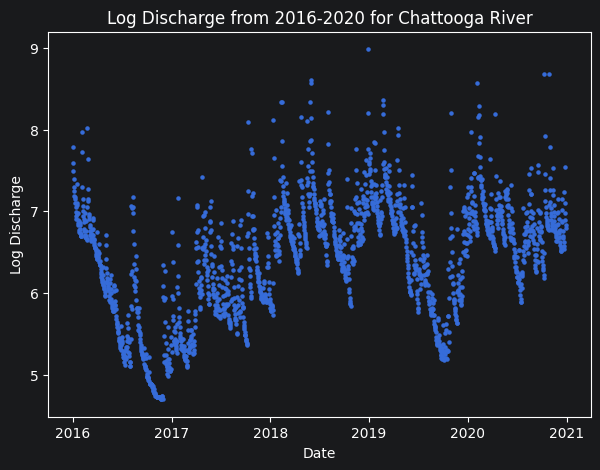

The falls are gradual and the rises are sharper


In [148]:
raw['log_discharge'] = np.log(raw['discharge_cfs'])

chat = raw[(raw['site'] == '02177000') & (raw['year'] >= 2016) & (raw['year'] <= 2020)]

fig, ax = plt.subplots(figsize=(7,5))
ax.scatter(chat.date, chat.log_discharge, label="Discharge", s=5)
ax.set_xlabel('Date')
ax.set_ylabel('Log Discharge')
ax.title.set_text('Log Discharge from 2016-2020 for Chattooga River')
plt.show()
print('The falls are gradual and the rises are sharper')

    2. Plot the distribution of daily discharge for all catchments together, first on a linear
scale and then after a $\log(1+x)$ transform. In one sentence, which is easier to model with a
squared-error loss, and why?

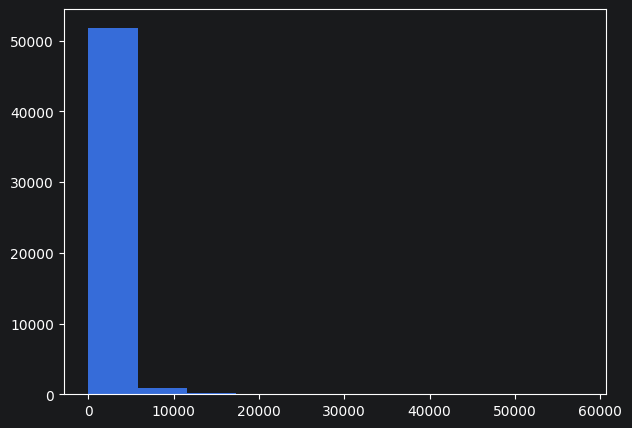

In [149]:
fig, ax = plt.subplots(figsize=(7,5))
plt.hist(raw['discharge_cfs'], label="Discharge")
plt.show()

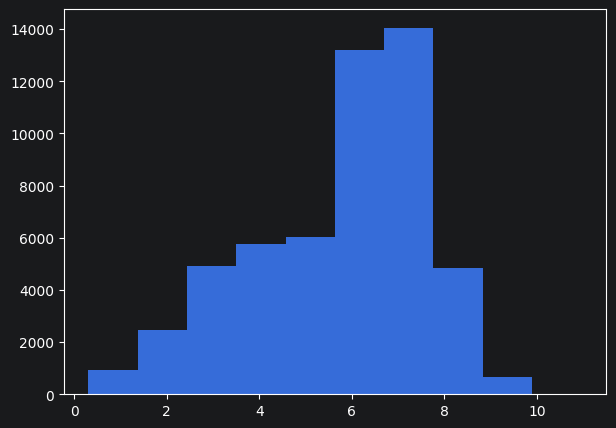

In [150]:
raw['transform_discharge'] = np.log(1 + raw['discharge_cfs'])

fig, ax = plt.subplots(figsize=(7,5))
plt.hist(raw['transform_discharge'], label="Discharge")
plt.show()

In [151]:
print('The raw values for discharge are very very right skewed while the log transformed version is more symmetrical and would be easier to model a mean squared loss')

The raw values for discharge are very very right skewed while the log transformed version is more symmetrical and would be easier to model a mean squared loss


3. Make a scatter plot of same-day discharge against same-day precipitation for one
catchment, and compute the correlation. It will be much weaker than you might expect.
In one sentence, give one physical reason why today's rainfall alone is a poor predictor of
today's flow.

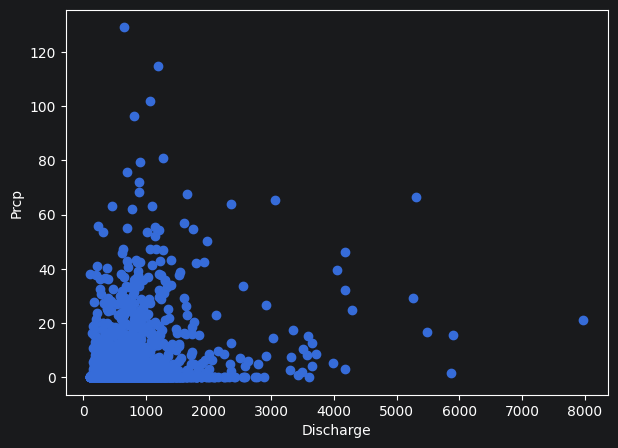

Correlation between discharge and prcp: 0.17250327546289457
Rainfall runoff depends on the history of the catchment and not just the rainfall for today


In [152]:
fig, ax = plt.subplots(figsize=(7,5))
ax.scatter(chat.discharge_cfs, chat.prcp)
ax.set_xlabel('Discharge')
ax.set_ylabel('Prcp')
plt.show()

correlation = chat['discharge_cfs'].corr(chat['prcp'])
print('Correlation between discharge and prcp: ' + str(correlation))
print('Rainfall runoff depends on the history of the catchment and not just the rainfall for today')

4. Catchments differ enormously in size, so their discharges are not comparable. The New
River drains 26 times the area of Marsh Creek. Create a column `logQ` holding
$\log(1 + Q/A)$, where $Q$ is discharge in cfs and $A$ is drainage area in square miles.
Plot the distribution of `logQ` for each catchment on shared axes and confirm that they now
overlap.

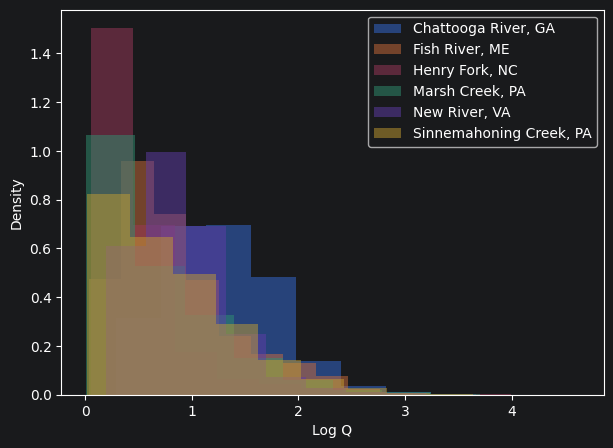

They do overlap


In [153]:
raw['logQ'] = np.log(1 + (raw['discharge_cfs'] / raw['area_sq_mi']))
grouped_raw = raw.groupby('name')

fig, ax = plt.subplots(figsize=(7,5))
for name, catchment in raw.groupby('name'):
    ax.hist(catchment['logQ'], density = True, alpha = 0.5, label = name)
ax.set_xlabel('Log Q')
ax.set_ylabel('Density')
ax.legend()
plt.show()

print('They do overlap')

## Part 2: Build the features

A network given only today's weather cannot know whether the ground is already saturated.
The catchment's *memory* has to be supplied explicitly, as features describing the recent
past.

5. Working **within each catchment separately** (use `groupby("site")` so that lags and
rolling totals never run from one catchment's record into the next), construct:

- `prcp_lag1` through `prcp_lag10`: precipitation on each of the previous ten days
- `prcp_sum3`, `prcp_sum7`, `prcp_sum14`, `prcp_sum30`, `prcp_sum90`: rolling
  precipitation totals, which act as proxies for how wet the catchment already is
- `tmean_7` and `tmean_30`, rolling mean temperature, a proxy for evaporative demand and
  for whether precipitation is falling as snow
- `doy_sin` and `doy_cos`, the day of year encoded as a pair of sinusoids

In [154]:
raw['tmean'] = (raw['tmax'] + raw['tmin']) / 2
doy = raw["date"].dt.dayofyear
raw["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
raw["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)
grouped = raw.groupby('site')

# Had help from AI on how to structure the code to iteratively create features rather than typing it all out and also for rolling mean and sum
for i in range(1, 11):
    raw[f"prcp_lag{i}"] = grouped['prcp'].shift(i)

for j in [3, 7, 14, 30, 90]:
    raw[f"prcp_sum{j}"] = grouped['prcp'].transform(lambda x: x.rolling(j).sum())

for k in [7, 30]:
    raw[f"tmean_{k}"] = grouped['prcp'].transform(lambda x: x.rolling(k).mean())

raw.head(10)

,year,yday,prcp,tmax,tmin,date,discharge_cfs,site,name,area_sq_mi,...,prcp_lag8,prcp_lag9,prcp_lag10,prcp_sum3,prcp_sum7,prcp_sum14,prcp_sum30,prcp_sum90,tmean_7,tmean_30
0,1995,1,0.00,13.42,3.80,1995-01-01,643.0,02177000,"Chattooga River, GA",207.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1995,2,0.00,9.22,-2.67,1995-01-02,588.0,02177000,"Chattooga River, GA",207.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1995,3,0.00,7.03,-4.34,1995-01-03,564.0,02177000,"Chattooga River, GA",207.0,...,NaN,NaN,NaN,0.00,NaN,NaN,NaN,NaN,NaN,NaN
3,1995,4,0.00,5.93,-5.19,1995-01-04,557.0,02177000,"Chattooga River, GA",207.0,...,NaN,NaN,NaN,0.00,NaN,NaN,NaN,NaN,NaN,NaN
4,1995,5,0.00,4.55,-10.18,1995-01-05,540.0,02177000,"Chattooga River, GA",207.0,...,NaN,NaN,NaN,0.00,NaN,NaN,NaN,NaN,NaN,NaN
5,1995,6,35.67,6.11,-8.40,1995-01-06,603.0,02177000,"Chattooga River, GA",207.0,...,NaN,NaN,NaN,35.67,NaN,NaN,NaN,NaN,NaN,NaN
6,1995,7,0.00,8.69,-2.39,1995-01-07,1510.0,02177000,"Chattooga River, GA",207.0,...,NaN,NaN,NaN,35.67,35.67,NaN,NaN,NaN,5.095714,NaN
7,1995,8,0.00,11.28,-4.38,1995-01-08,914.0,02177000,"Chattooga River, GA",207.0,...,NaN,NaN,NaN,35.67,35.67,NaN,NaN,NaN,5.095714,NaN
8,1995,9,0.00,13.12,-3.13,1995-01-09,785.0,02177000,"Chattooga River, GA",207.0,...,0.0,NaN,NaN,0.00,35.67,NaN,NaN,NaN,5.095714,NaN
9,1995,10,0.00,12.35,-1.87,1995-01-10,723.0,02177000,"Chattooga River, GA",207.0,...,0.0,0.0,NaN,0.00,35.67,NaN,NaN,NaN,5.095714,NaN


6. Also within each catchment, construct `logQ_lag0` through `logQ_lag3`, the
area-normalized log discharge today and on the three previous days. These are the single
most informative features you will build: rivers have long memories.

Then create the **target**, `target`, as `logQ` **three days in the future**. This makes the
task a three-day-ahead forecast.

In [155]:
for i in range(4):
    raw[f"logQ_lag{i}"] = grouped['logQ'].shift(i)

raw['target'] = grouped['logQ'].shift(-3)
raw['target_date'] = grouped['date'].shift(-3)

7. Drop rows containing NaN (the lags and rolling windows leave gaps at the start of each
catchment's record, and the target leaves gaps at the end). Assemble the feature matrix `X`
from all the engineered features plus `area_sq_mi`, `lat` and `lon`, and the target vector
`y`. Report the shapes and the number of features.

In [156]:
raw = raw.dropna().reset_index(drop=True)

# Had help from AI to select all the columns without having to type them out
features = [c for c in raw.columns
                if c.startswith(("prcp_", "tmean_", "doy_", "logQ_lag"))]
features += ["area_sq_mi", "lat", "lon"]
X = raw[features]
y = raw['target']

print('X shape: ' + str(X.shape))
print('y shape: ' + str(y.shape))
print('Number of features: ' + str(X.shape[1]))


X shape: (52358, 26)
y shape: (52358,)
Number of features: 26


## Part 3: Splitting and scaling

8. Split the data by date: train on everything before 2014,
validate on 2014–2016, and test on 2017 onwards. Report the size of each split.

In [157]:
train = raw['year'] < 2014
val = raw['year'].between(2014, 2016)
test = raw['year'] >= 2017

X_train, y_train = X[train], y[train]
X_val, y_val = X[val], y[val]
X_test, y_test = X[test], y[test]

print(f"length of training set: {len(X_train):,}, length of validation set: {len(X_val):,}, length of test set: {len(y_test):,}")

length of training set: 37,542, length of validation set: 6,531, length of test set: 8,285


9. Scale the features with `StandardScaler`. Fit the scaler on the training set,
then transform all three sets with it.

In [158]:
x_scaler = StandardScaler().fit(X_train)
y_scaler = StandardScaler().fit(y_train.to_numpy().reshape(-1, 1))

def scale_x(df):  return x_scaler.transform(df)
def scale_y(s):   return y_scaler.transform(s.to_numpy().reshape(-1, 1))

Xs_train, Xs_valid, Xs_test = scale_x(X_train), scale_x(X_val), scale_x(X_test)
ys_train, ys_valid, ys_test = scale_y(y_train), scale_y(y_val), scale_y(y_test)

## Part 4: Train a neural network

10. Using `tensorflow`, build a fully connected network that takes the feature matrix as
input and has three hidden `Dense` layers of 128, 64 and 32 units with `ReLU` activation,
followed by a final `Dense` layer with a single output and no activation.

In [159]:
tf.keras.backend.clear_session()
tf.random.set_seed(27)

n_features = Xs_train.shape[1]
l2 = tf.keras.regularizers.l2(0.03)   # L2 penalty on each hidden layer's weights
model = tf.keras.Sequential([
    tf.keras.Input(shape=[n_features]),
    tf.keras.layers.Dense(128, activation="relu", kernel_regularizer=l2),
    tf.keras.layers.Dense(64, activation="relu", kernel_regularizer=l2),
    tf.keras.layers.Dense(32, activation="relu", kernel_regularizer=l2),
    tf.keras.layers.Dense(1) # Output layer, just one neuron
])

11. Print the model summary. How many trainable parameters does it have?

In [160]:
model.summary()
print('Number of trainable parameters = 13,825')

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         3,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,825 (54.00 KB)

 Trainable params: 13,825 (54.00 KB)

 Non-trainable params: 0 (0.00 B)

Number of trainable parameters = 13,825


12. Compile the model with MSE loss and the `Adam` optimizer, including root mean squared error as a metric.

In [161]:
model.compile(loss="mse",
              optimizer=tf.keras.optimizers.Adam(),
              metrics=["mse"]) # mean squared error

13. Train the model for up to 200 epochs using the validation set, with an `EarlyStopping`
callback (`patience=20`, `restore_best_weights=True`). Report the epoch it stopped at.

In [162]:
early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=20,
                                              restore_best_weights=True)
history = model.fit(Xs_train, ys_train, epochs=200,
                    validation_data=(Xs_valid, ys_valid),
                    callbacks=[early_stop], verbose=0)
best_epoch = int(np.argmin(history.history["val_loss"])) + 1
print(f"Stopped after {len(history.epoch)} epochs and kept the weights from epoch {best_epoch}.")

Stopped after 200 epochs and kept the weights from epoch 196.


14. Plot the training and validation loss against epoch number.

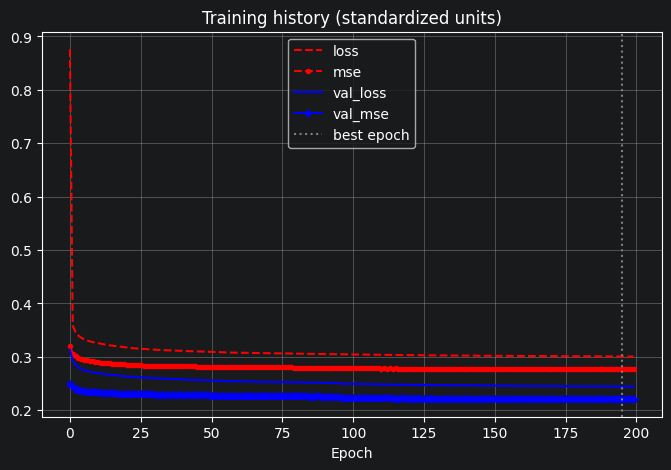

In [163]:
ax = pd.DataFrame(history.history).plot(
    figsize=(8, 5), grid=True, xlabel="Epoch",
    style=["r--", "r--.", "b-", "b-*"])
ax.axvline(best_epoch - 1, color="gray", linestyle=":", label="best epoch")
ax.legend()
plt.title("Training history (standardized units)")
plt.show()

15. Save the trained model.

In [164]:
model.save("streamflow_nn_model.keras")

## Part 5: Evaluate

16. Evaluate the model on the **test** set and report the MSE and RMSE. Then compute the
$R^2$ between predicted and observed `logQ`.

In [165]:
y_pred_keras = y_scaler.inverse_transform(model.predict(Xs_test, verbose=0)).ravel()
r2_keras = r2_score(y_test, y_pred_keras)
print(f"Keras test R^2: {r2_keras:.3f}")

Keras test R^2: 0.709


17. A score means nothing without a baseline. Compare your network against two:

- **Persistence**: predict that the flow in three days equals today's flow
  (`logQ_lag0`). This is what a forecaster with no model at all would say, and on a river
  it is a genuinely strong prediction.
- **Linear regression**: the same features, fitted with `LinearRegression`.

Report $R^2$ for all three on the test set, in one table.

In [166]:
y_pred_persist = X_test['logQ_lag0']
r2_persist = r2_score(y_test, y_pred_persist)
print(f"Persistence test R^2: {r2_persist:.3f}")

y_pred_linear_reg = LinearRegression().fit(Xs_train, y_train).predict(Xs_test)
r2_linear_reg = r2_score(y_test, y_pred_linear_reg)
print(f"Linear Regression test R^2: {r2_linear_reg:.3f}")

r2_table = [
    ("Persistence", r2_persist),
    ("Linear regression", r2_linear_reg),
    ("Neural network", r2_keras),
]

print(r2_table)


Persistence test R^2: 0.584
Linear Regression test R^2: 0.679
[('Persistence', 0.5837599042315784), ('Linear regression', 0.678553300269866), ('Neural network', 0.7091128722626616)]


/Users/deborah/Desktop/Masters/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/deborah/Desktop/Masters/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/deborah/Desktop/Masters/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


18. Make a scatter plot of predicted against observed `logQ` for the test set, with a 1:1
line. In one sentence, where in the range does the model do worst?

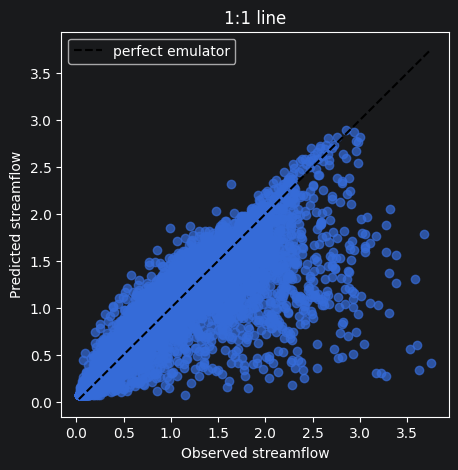

The model does worst for the high values of observed streamflow


In [167]:
plt.figure(figsize=(5, 5))
plt.scatter(y_test, y_pred_keras, alpha=0.7)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, "k--", label="perfect emulator")
plt.xlabel("Observed streamflow")
plt.ylabel("Predicted streamflow")
plt.title("1:1 line")
plt.legend()
plt.show()

print('The model does worst for the high values of observed streamflow')

19. Plot the observed and predicted hydrograph for one catchment over a single test year, so
that the two curves can be compared day by day. In one sentence, does the model capture the
timing and the size of the peaks?

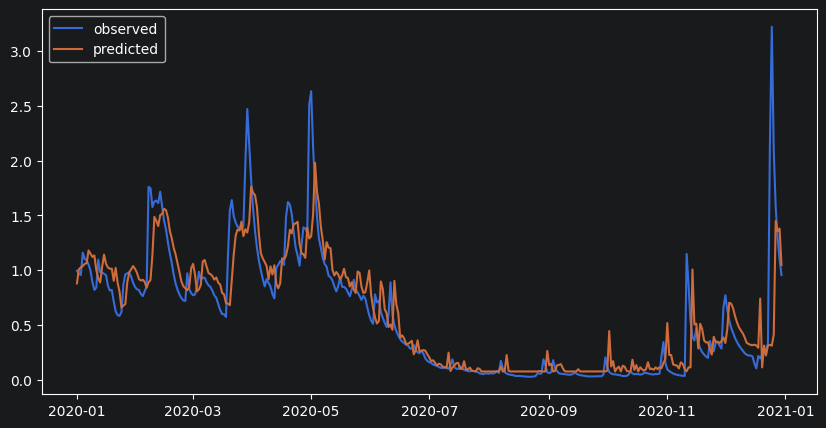

In [168]:
fig, ax = plt.subplots(figsize=(10, 5))

results = raw[test][['name', 'target_date']].copy()
results['observed'] = y_test
results['predicted'] = y_pred_keras

name = 'Marsh Creek, PA'
year = 2020

marsh_results = results[(results['name'] == name) & (results['target_date'].dt.year == year)]

ax.plot(marsh_results['target_date'], marsh_results['observed'], label="observed")
ax.plot(marsh_results['target_date'], marsh_results['predicted'], label="predicted")
ax.legend()
plt.show()

In [169]:
print('The model does not quite capture the timing and height of the peaks. The model is always a little behind the actual and the predicted peaks are not as high as they actually are.')

The model does not quite capture the timing and height of the peaks. The model is always a little behind the actual and the predicted peaks are not as high as they actually are.
